# Environmental Toxin Analysis in River Systems

## 1. Project Overview

This project uses exploratory data analysis to investigate toxin levels and water quality across multiple river systems.

The analysis examines patterns in toxin concentrations, changes over time, seasonal variation and relationships between pH levels and toxins.

The aim is to identify key environmental patterns and develop evidence-based recommendations for EcoGuard.


## 2. Tools and Libraries

The analysis uses Python and the following libraries:

- **Python 3** – programming language.
- **JupyterLab** – development environment.
- **pandas** – data inspection, cleaning and manipulation.
- **NumPy** – numerical operations.
- **Matplotlib** – data visualisation.
- **Seaborn** – statistical visualisation.
- **SciPy** – statistical testing and analysis.

## 3. Project Objectives

The objectives of this project are to:

- Compare and rank river systems according to their toxin concentrations.
- Investigate changes in toxin levels over time.
- Examine relationships between pH levels and toxin concentrations.
- Explore seasonal patterns in toxin levels.
- Compare toxin levels between selected river systems using statistical testing.
- Investigate whether pH levels can help predict toxin concentrations using linear regression.
- Present key findings and evidence-based recommendations for EcoGuard.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.stats import linregress

In [2]:
df = pd.read_csv("../data/National_River_Toxin_Dataset_1.csv")

In [3]:
df.head()

,Date,River_System,pH_Level,Temperature,Lead,Mercury,Arsenic,Nitrates,Phosphates,Dissolved_Oxygen
0,2018-01-01,Amazon,7.030015,19.136212,2.500401,0.465454,3.578886,11.627614,0.522167,7.830196
1,2018-01-01,Nile,7.421766,21.406824,3.469443,0.859716,5.352155,10.538171,0.510465,8.130328
2,2018-01-01,Yangtze,7.133612,18.419902,3.806935,0.824085,5.277814,7.865033,0.585096,8.120874
3,2018-01-01,Mississippi,7.863001,18.014871,3.438131,0.500597,3.473881,11.143068,0.438248,6.853816
4,2018-01-01,Danube,7.527686,16.622289,2.188210,0.424178,2.454209,8.043467,0.422244,8.197925


In [4]:
df.shape

(1305, 10)

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1305 entries, 0 to 1304
Data columns (total 10 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Date              1305 non-null   str    
 1   River_System      1305 non-null   str    
 2   pH_Level          1278 non-null   float64
 3   Temperature       1278 non-null   float64
 4   Lead              1285 non-null   float64
 5   Mercury           1278 non-null   float64
 6   Arsenic           1279 non-null   float64
 7   Nitrates          1265 non-null   float64
 8   Phosphates        1282 non-null   float64
 9   Dissolved_Oxygen  1284 non-null   float64
dtypes: float64(8), str(2)
memory usage: 123.5 KB


In [6]:
df.isnull().sum()

Date                 0
River_System         0
pH_Level            27
Temperature         27
Lead                20
Mercury             27
Arsenic             26
Nitrates            40
Phosphates          23
Dissolved_Oxygen    21
dtype: int64

In [7]:
df.duplicated().sum()

np.int64(0)

In [8]:
df['River_System'].nunique()

5

In [9]:
df['River_System'].unique()

<ArrowStringArray>
['Amazon', 'Nile', 'Yangtze', 'Mississippi', 'Danube']
Length: 5, dtype: str

In [10]:
df['Date'].min(), df['Date'].max()

('2018-01-01', '2022-12-26')

In [11]:
df['Date'] = pd.to_datetime(df['Date'])

In [12]:
df['Date'].dtype

dtype('<M8[us]')

In [13]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1305 entries, 0 to 1304
Data columns (total 10 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   Date              1305 non-null   datetime64[us]
 1   River_System      1305 non-null   str           
 2   pH_Level          1278 non-null   float64       
 3   Temperature       1278 non-null   float64       
 4   Lead              1285 non-null   float64       
 5   Mercury           1278 non-null   float64       
 6   Arsenic           1279 non-null   float64       
 7   Nitrates          1265 non-null   float64       
 8   Phosphates        1282 non-null   float64       
 9   Dissolved_Oxygen  1284 non-null   float64       
dtypes: datetime64[us](1), float64(8), str(1)
memory usage: 110.7 KB


In [14]:
missing_percentage = (df.isnull().sum() / len(df)) * 100

missing_percentage

Date                0.000000
River_System        0.000000
pH_Level            2.068966
Temperature         2.068966
Lead                1.532567
Mercury             2.068966
Arsenic             1.992337
Nitrates            3.065134
Phosphates          1.762452
Dissolved_Oxygen    1.609195
dtype: float64

In [15]:
df.groupby('River_System').apply(lambda x: x.isnull().sum())

,Date,pH_Level,Temperature,Lead,Mercury,Arsenic,Nitrates,Phosphates,Dissolved_Oxygen
River_System,,,,,,,,,
Amazon,0,5,11,4,4,7,8,5,8
Danube,0,6,6,3,1,5,5,6,3
Mississippi,0,4,3,6,8,5,5,4,2
Nile,0,4,3,4,5,6,4,5,4
Yangtze,0,8,4,3,9,3,18,3,4


## 4. Initial Data Inspection and Quality Assessment

The dataset contains 1,305 records and 10 columns, covering five river systems between January 2018 and December 2022.

Initial data-quality checks identified:

- Missing values across several measurement columns, with Nitrates containing the highest number (40).
- A concentration of missing Phosphates measurements in the Yangtze river system (18 of 23 missing values).
- No fully duplicated records.
- The Date column was initially stored as text and was converted to datetime format to support time-based analysis.

Further investigation is required to determine the appropriate treatment of missing measurements before conducting the analysis.

In [16]:
df.isnull().any(axis=1).sum()

np.int64(199)

In [17]:
df.isnull().sum(axis=1).value_counts().sort_index()

0    1106
1     187
2      12
Name: count, dtype: int64

## 5. Missing Data Strategy

The dataset contains 211 missing values across 199 records. Most incomplete records contain only one missing measurement, while 12 records contain two missing measurements.

Rather than removing all incomplete records or automatically replacing missing measurements, the analysis will retain available data wherever possible. Calculations will use valid observations, while statistical tests and regression will use records with complete values for the variables involved.

This approach aims to preserve as much useful information as possible while avoiding unsupported assumptions about missing environmental measurements.

In [18]:
df.describe()

,Date,pH_Level,Temperature,Lead,Mercury,Arsenic,Nitrates,Phosphates,Dissolved_Oxygen
count,1305,1278.000000,1278.000000,1285.000000,1278.000000,1279.000000,1265.000000,1282.000000,1284.000000
mean,2020-06-29 00:00:00,7.353247,20.041668,3.011035,0.596108,3.597916,10.038789,0.497162,8.023795
min,2018-01-01 00:00:00,6.465087,9.891618,0.551349,0.157117,1.485608,2.025075,0.144044,5.041394
25%,2019-04-01 00:00:00,7.101324,16.813976,2.366298,0.462683,2.836160,8.701188,0.422006,7.269386
50%,2020-06-29 00:00:00,7.339326,20.039121,3.000714,0.599186,3.511678,10.089112,0.497631,8.007448
75%,2021-09-27 00:00:00,7.585733,23.358634,3.676560,0.734863,4.298946,11.391686,0.572888,8.740828
max,2022-12-26 00:00:00,8.392902,30.749449,5.800963,1.057494,6.232902,16.547073,0.870007,11.228677
std,NaN,0.349114,4.063638,0.874431,0.175150,0.992052,2.096641,0.106304,1.064190


In [19]:
df.describe(include='number')

,pH_Level,Temperature,Lead,Mercury,Arsenic,Nitrates,Phosphates,Dissolved_Oxygen
count,1278.000000,1278.000000,1285.000000,1278.000000,1279.000000,1265.000000,1282.000000,1284.000000
mean,7.353247,20.041668,3.011035,0.596108,3.597916,10.038789,0.497162,8.023795
std,0.349114,4.063638,0.874431,0.175150,0.992052,2.096641,0.106304,1.064190
min,6.465087,9.891618,0.551349,0.157117,1.485608,2.025075,0.144044,5.041394
25%,7.101324,16.813976,2.366298,0.462683,2.836160,8.701188,0.422006,7.269386
50%,7.339326,20.039121,3.000714,0.599186,3.511678,10.089112,0.497631,8.007448
75%,7.585733,23.358634,3.676560,0.734863,4.298946,11.391686,0.572888,8.740828
max,8.392902,30.749449,5.800963,1.057494,6.232902,16.547073,0.870007,11.228677


## 6. Exploratory Data Analysis

### 6.1 Initial Observations from Descriptive Statistics

The descriptive statistics show variation across all measured water-quality indicators and toxin concentrations.

The average pH level is approximately 7.35, while temperature measurements range from 9.89 to 30.75. Toxin measurements also show variation, particularly for lead, arsenic and nitrates.

The number of available observations differs between variables because of missing measurements. These overall statistics provide an initial understanding of the dataset, but further analysis is needed to identify differences between river systems and patterns over time.

Individual toxin concentrations will be considered separately rather than compared directly using their raw numerical values, as their measurement units and environmental significance may differ.

In [20]:
river_averages = df.groupby('River_System').mean(numeric_only=True)

river_averages

,pH_Level,Temperature,Lead,Mercury,Arsenic,Nitrates,Phosphates,Dissolved_Oxygen
River_System,,,,,,,,
Amazon,6.984401,20.029672,2.015404,0.491959,3.005612,9.883220,0.504355,8.008012
Danube,7.311050,20.123258,2.539492,0.396511,2.496212,9.987329,0.498761,7.902202
Mississippi,7.803676,19.913761,3.489190,0.598581,3.490920,10.138178,0.502774,8.033731
Nile,7.469010,20.113982,2.989879,0.708797,3.997052,10.240214,0.493598,8.153453
Yangtze,7.193857,20.028194,4.022830,0.791298,4.985871,9.937239,0.486391,8.021728


In [21]:
river_averages.sort_values(
    by='Lead',
    ascending=False
)

,pH_Level,Temperature,Lead,Mercury,Arsenic,Nitrates,Phosphates,Dissolved_Oxygen
River_System,,,,,,,,
Yangtze,7.193857,20.028194,4.022830,0.791298,4.985871,9.937239,0.486391,8.021728
Mississippi,7.803676,19.913761,3.489190,0.598581,3.490920,10.138178,0.502774,8.033731
Nile,7.469010,20.113982,2.989879,0.708797,3.997052,10.240214,0.493598,8.153453
Danube,7.311050,20.123258,2.539492,0.396511,2.496212,9.987329,0.498761,7.902202
Amazon,6.984401,20.029672,2.015404,0.491959,3.005612,9.883220,0.504355,8.008012


In [22]:
river_averages.sort_values(
    by='Mercury',
    ascending=False
)

,pH_Level,Temperature,Lead,Mercury,Arsenic,Nitrates,Phosphates,Dissolved_Oxygen
River_System,,,,,,,,
Yangtze,7.193857,20.028194,4.022830,0.791298,4.985871,9.937239,0.486391,8.021728
Nile,7.469010,20.113982,2.989879,0.708797,3.997052,10.240214,0.493598,8.153453
Mississippi,7.803676,19.913761,3.489190,0.598581,3.490920,10.138178,0.502774,8.033731
Amazon,6.984401,20.029672,2.015404,0.491959,3.005612,9.883220,0.504355,8.008012
Danube,7.311050,20.123258,2.539492,0.396511,2.496212,9.987329,0.498761,7.902202


In [23]:
river_averages.sort_values(
    by='Arsenic',
    ascending=False
)

,pH_Level,Temperature,Lead,Mercury,Arsenic,Nitrates,Phosphates,Dissolved_Oxygen
River_System,,,,,,,,
Yangtze,7.193857,20.028194,4.022830,0.791298,4.985871,9.937239,0.486391,8.021728
Nile,7.469010,20.113982,2.989879,0.708797,3.997052,10.240214,0.493598,8.153453
Mississippi,7.803676,19.913761,3.489190,0.598581,3.490920,10.138178,0.502774,8.033731
Amazon,6.984401,20.029672,2.015404,0.491959,3.005612,9.883220,0.504355,8.008012
Danube,7.311050,20.123258,2.539492,0.396511,2.496212,9.987329,0.498761,7.902202


In [24]:
river_averages.sort_values(
    by='Nitrates',
    ascending=False
)

,pH_Level,Temperature,Lead,Mercury,Arsenic,Nitrates,Phosphates,Dissolved_Oxygen
River_System,,,,,,,,
Nile,7.469010,20.113982,2.989879,0.708797,3.997052,10.240214,0.493598,8.153453
Mississippi,7.803676,19.913761,3.489190,0.598581,3.490920,10.138178,0.502774,8.033731
Danube,7.311050,20.123258,2.539492,0.396511,2.496212,9.987329,0.498761,7.902202
Yangtze,7.193857,20.028194,4.022830,0.791298,4.985871,9.937239,0.486391,8.021728
Amazon,6.984401,20.029672,2.015404,0.491959,3.005612,9.883220,0.504355,8.008012


In [25]:
river_averages.sort_values(
    by='Phosphates',
    ascending=False
)

,pH_Level,Temperature,Lead,Mercury,Arsenic,Nitrates,Phosphates,Dissolved_Oxygen
River_System,,,,,,,,
Amazon,6.984401,20.029672,2.015404,0.491959,3.005612,9.883220,0.504355,8.008012
Mississippi,7.803676,19.913761,3.489190,0.598581,3.490920,10.138178,0.502774,8.033731
Danube,7.311050,20.123258,2.539492,0.396511,2.496212,9.987329,0.498761,7.902202
Nile,7.469010,20.113982,2.989879,0.708797,3.997052,10.240214,0.493598,8.153453
Yangtze,7.193857,20.028194,4.022830,0.791298,4.985871,9.937239,0.486391,8.021728


### 6.2 Comparing Average Toxin Concentrations Across River Systems

The average toxin concentrations were compared across the five river systems to identify differences in water-quality measurements.

Key observations:

- The Yangtze recorded the highest average concentrations of Lead, Mercury and Arsenic.
- The Nile recorded the highest average Nitrates concentration.
- The Amazon recorded the highest average Phosphates concentration, although differences between river systems were small.

The results show that different river systems have higher average concentrations for different substances. No single overall pollution ranking has been calculated because the measurements may have different units and environmental significance.

Further analysis is required to investigate changes over time, seasonal patterns and relationships between water-quality indicators.

In [26]:
river_averages_plot = river_averages.reset_index()
river_averages_plot.head()

,River_System,pH_Level,Temperature,Lead,Mercury,Arsenic,Nitrates,Phosphates,Dissolved_Oxygen
0,Amazon,6.984401,20.029672,2.015404,0.491959,3.005612,9.883220,0.504355,8.008012
1,Danube,7.311050,20.123258,2.539492,0.396511,2.496212,9.987329,0.498761,7.902202
2,Mississippi,7.803676,19.913761,3.489190,0.598581,3.490920,10.138178,0.502774,8.033731
3,Nile,7.469010,20.113982,2.989879,0.708797,3.997052,10.240214,0.493598,8.153453
4,Yangtze,7.193857,20.028194,4.022830,0.791298,4.985871,9.937239,0.486391,8.021728


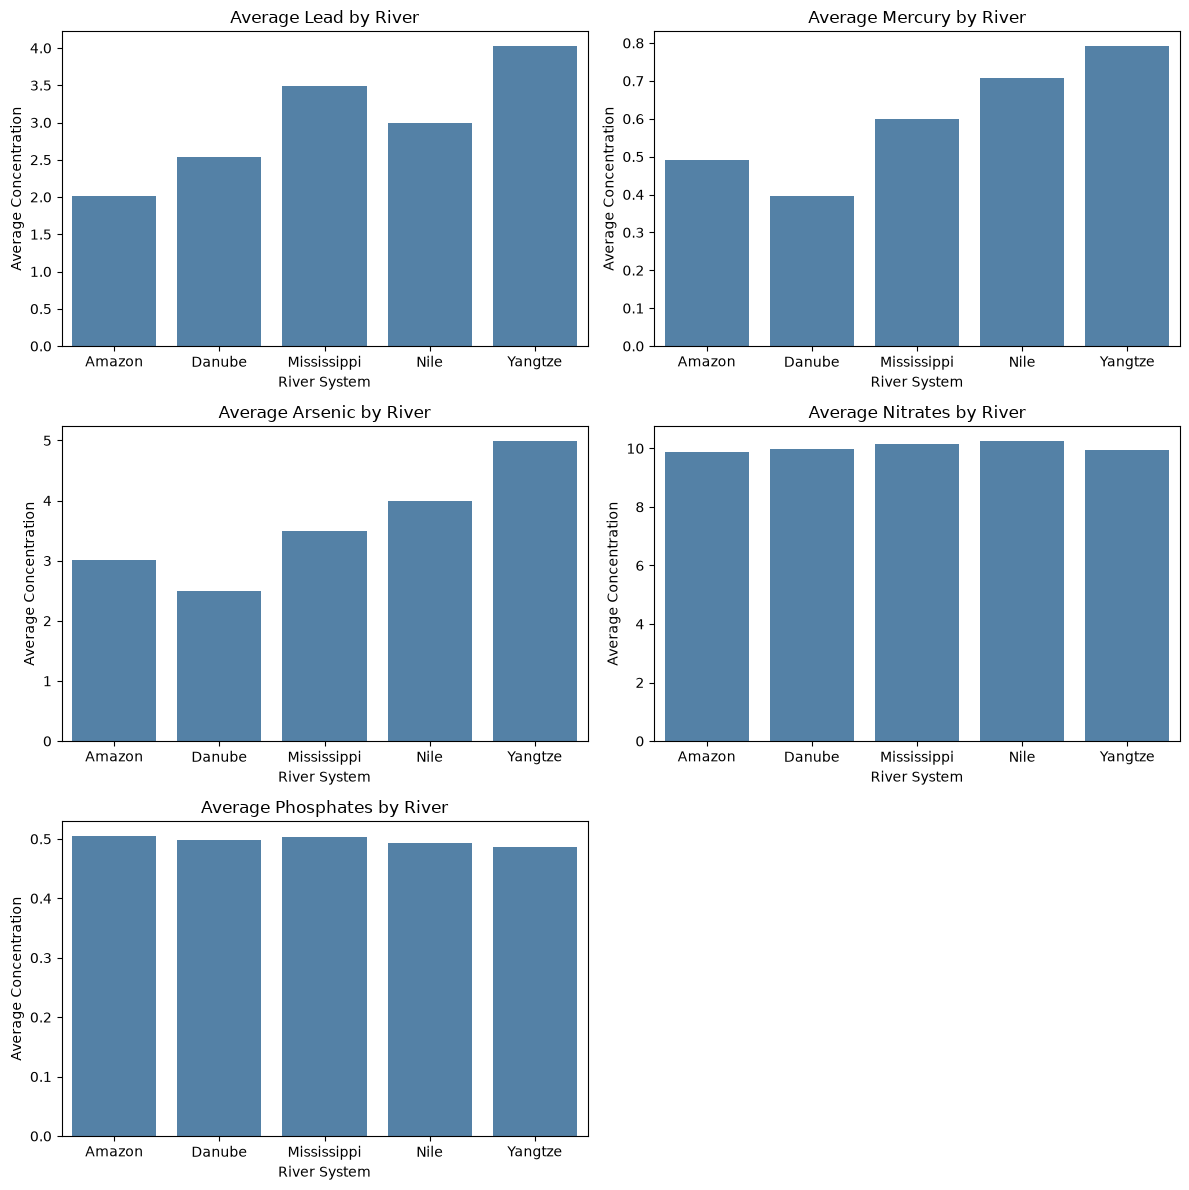

In [61]:

fig, axes = plt.subplots(
    3,
    2,
    figsize=(12, 12)
)

# Lead
sns.barplot(
    data=river_averages_plot,
    x='River_System',
    y='Lead',
    color='steelblue',
    ax=axes[0, 0]
)
axes[0, 0].set_title('Average Lead by River')

# Mercury
sns.barplot(
    data=river_averages_plot,
    x='River_System',
    y='Mercury',
    color='steelblue',
    ax=axes[0, 1]
)
axes[0, 1].set_title('Average Mercury by River')

# Arsenic
sns.barplot(
    data=river_averages_plot,
    x='River_System',
    y='Arsenic',
    color='steelblue',
    ax=axes[1, 0]
)
axes[1, 0].set_title('Average Arsenic by River')

# Nitrates
sns.barplot(
    data=river_averages_plot,
    x='River_System',
    y='Nitrates',
    color='steelblue',
    ax=axes[1, 1]
)
axes[1, 1].set_title('Average Nitrates by River')

# Phosphates
sns.barplot(
    data=river_averages_plot,
    x='River_System',
    y='Phosphates',
    color='steelblue',
    ax=axes[2, 0]
)
axes[2, 0].set_title('Average Phosphates by River')

# Axis labels
for ax in fig.axes:
    ax.set_xlabel('River System')
    ax.set_ylabel('Average Concentration')

# Remove unused chart space
fig.delaxes(axes[2, 1])

# Final formatting
plt.tight_layout()

plt.tight_layout()

plt.savefig(
    '../outputs/Average_Toxin_Concentrations_by_River.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

plt.show()


In [28]:
monthly_lead = df.groupby(
    [df['Date'].dt.to_period('M'), 'River_System']
)['Lead'].mean()

monthly_lead = monthly_lead.reset_index()

monthly_lead['Date'] = pd.to_datetime(
    monthly_lead['Date'].astype(str)
)

In [29]:
monthly_lead['Date'].dtype

dtype('<M8[us]')

In [30]:
print(monthly_lead.dtypes)
print(monthly_lead.head())

Date            datetime64[us]
River_System               str
Lead                   float64
dtype: object
        Date River_System      Lead
0 2018-01-01       Amazon  2.137385
1 2018-01-01       Danube  2.239415
2 2018-01-01  Mississippi  3.731348
3 2018-01-01         Nile  3.129493
4 2018-01-01      Yangtze  4.346036


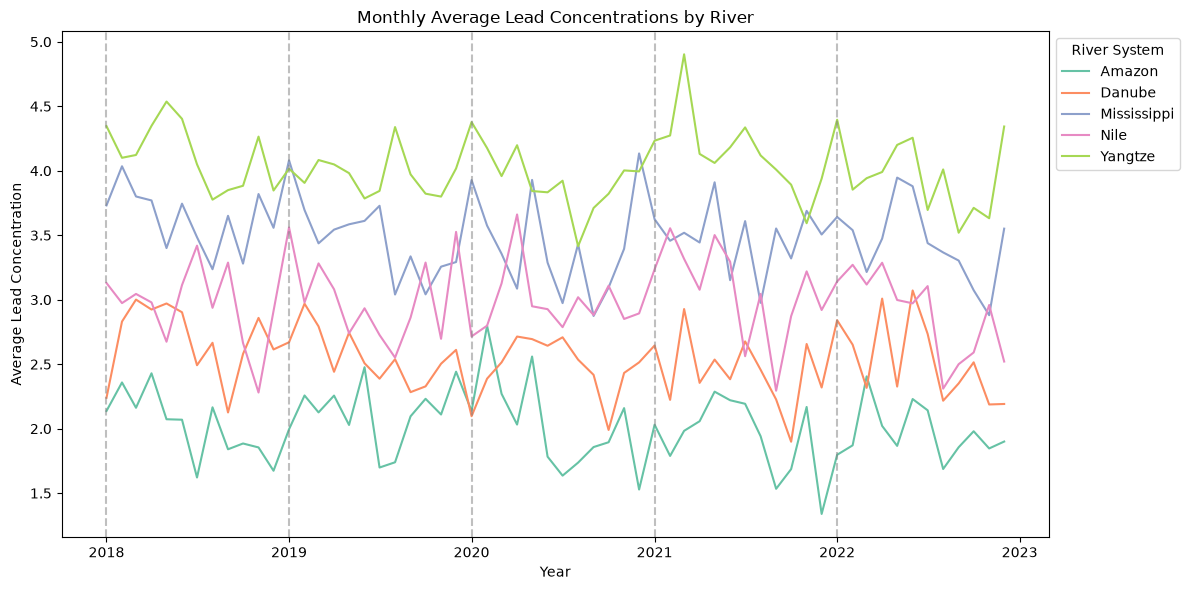

In [62]:
plt.figure(figsize=(12, 6))

sns.lineplot(
    data=monthly_lead,
    x='Date',
    y='Lead',
    hue='River_System',
    palette='Set2'
)

# Show January labels only
import matplotlib.dates as mdates

plt.gca().xaxis.set_major_locator(mdates.YearLocator())
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%Y'))

# Add vertical lines to separate each year
for year in range(2018, 2023):
    plt.axvline(
        pd.Timestamp(f'{year}-01-01'),
        color='grey',
        linestyle='--',
        alpha=0.5
    )

# Chart titles and labels
plt.title('Monthly Average Lead Concentrations by River')
plt.xlabel('Year')
plt.ylabel('Average Lead Concentration')
plt.xticks(rotation=0)

# Final formatting
plt.legend(title='River System', loc='upper left', bbox_to_anchor=(1, 1))
plt.tight_layout()

plt.savefig(
    '../outputs/Monthly_Lead_Trends_by_River.png',
    dpi=300,
    bbox_inches='tight'
)
plt.show()

In [32]:
monthly_mercury = df.groupby(
    [df['Date'].dt.to_period('M'), 'River_System']
)['Mercury'].mean()

In [33]:
monthly_mercury = monthly_mercury.reset_index()

monthly_mercury['Date'] = pd.to_datetime(
    monthly_mercury['Date'].astype(str)
)

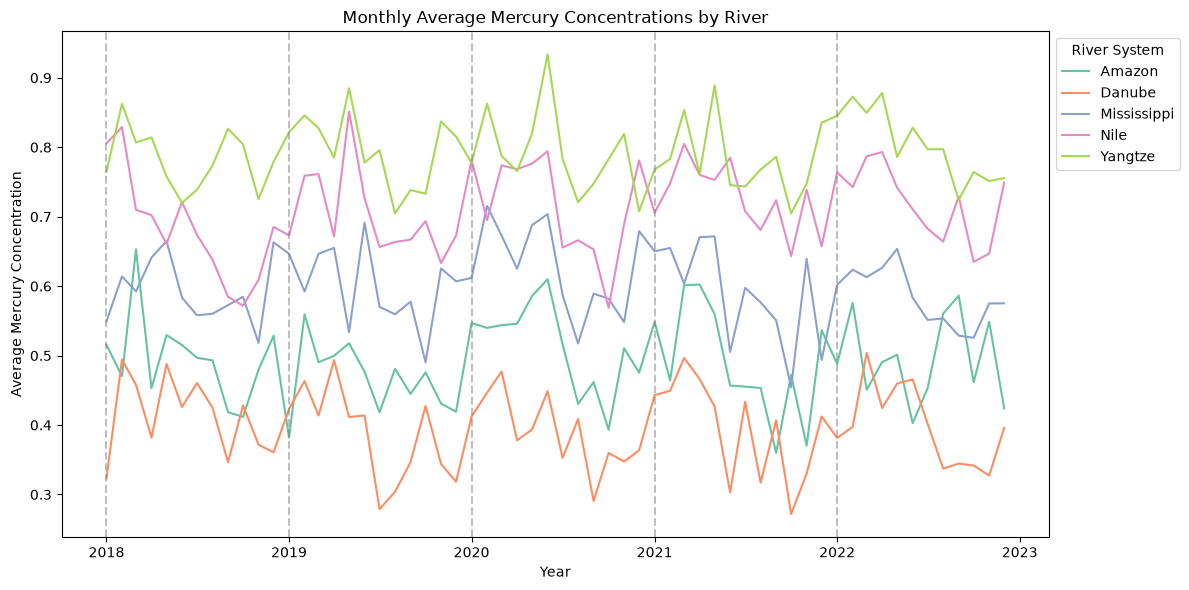

In [63]:
plt.figure(figsize=(12, 6))

sns.lineplot(
    data=monthly_mercury,
    x='Date',
    y='Mercury',
    hue='River_System',
    palette='Set2'
)

# Show January labels only
import matplotlib.dates as mdates

plt.gca().xaxis.set_major_locator(mdates.YearLocator())
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%Y'))

# Add vertical lines to separate each year
for year in range(2018, 2023):
    plt.axvline(
        pd.Timestamp(f'{year}-01-01'),
        color='grey',
        linestyle='--',
        alpha=0.5
    )

# Chart titles and labels
plt.title('Monthly Average Mercury Concentrations by River')
plt.xlabel('Year')
plt.ylabel('Average Mercury Concentration')

# Final formatting
plt.legend(title='River System', loc='upper left', bbox_to_anchor=(1, 1))
plt.tight_layout()

plt.savefig(
    '../outputs/Monthly_Mercury_Trends_by_River.png',
    dpi=300,
    bbox_inches='tight'
)
plt.show()

In [35]:
monthly_arsenic = df.groupby(
    [df['Date'].dt.to_period('M'), 'River_System']
)['Arsenic'].mean()

In [36]:
monthly_arsenic = monthly_arsenic.reset_index()

monthly_arsenic['Date'] = pd.to_datetime(
    monthly_arsenic['Date'].astype(str)
)

monthly_arsenic.head()

,Date,River_System,Arsenic
0,2018-01-01,Amazon,3.070699
1,2018-01-01,Danube,2.333455
2,2018-01-01,Mississippi,3.433624
3,2018-01-01,Nile,4.073082
4,2018-01-01,Yangtze,4.800956


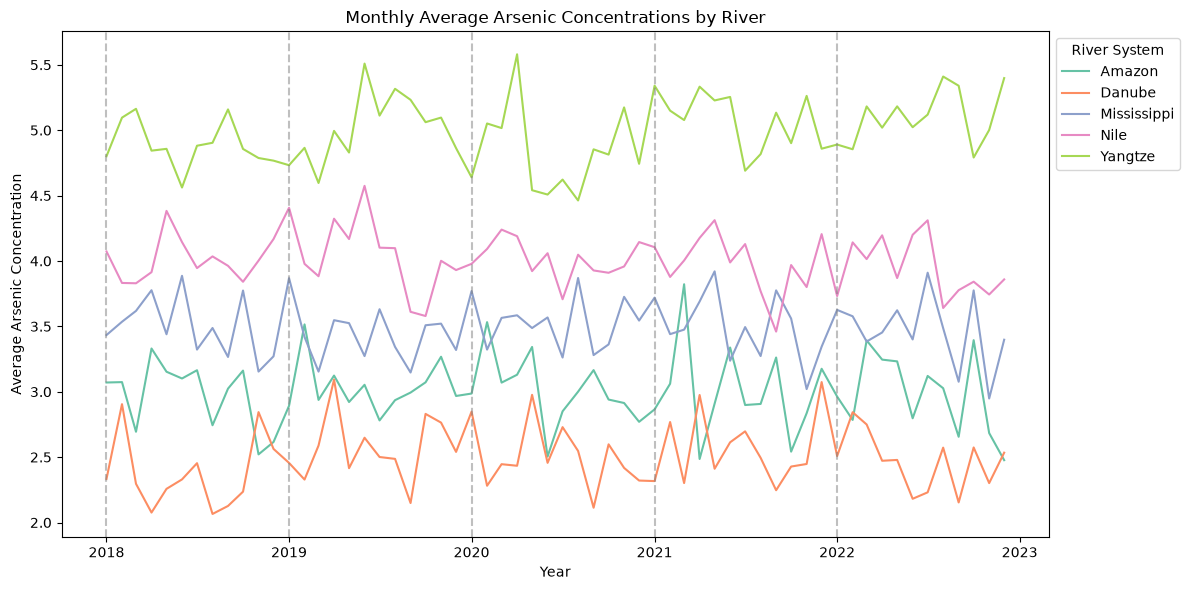

In [64]:
plt.figure(figsize=(12, 6))

sns.lineplot(
    data=monthly_arsenic,
    x='Date',
    y='Arsenic',
    hue='River_System',
    palette='Set2'
)

# Show January labels only
import matplotlib.dates as mdates

plt.gca().xaxis.set_major_locator(mdates.YearLocator())
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%Y'))

# Add vertical lines to separate each year
for year in range(2018, 2023):
    plt.axvline(
        pd.Timestamp(f'{year}-01-01'),
        color='grey',
        linestyle='--',
        alpha=0.5
    )

# Chart titles and labels
plt.title('Monthly Average Arsenic Concentrations by River')
plt.xlabel('Year')
plt.ylabel('Average Arsenic Concentration')

# Position legend on the right
plt.legend(
    title='River System',
    loc='upper left',
    bbox_to_anchor=(1, 1)
)

# Final formatting
plt.tight_layout()

plt.savefig(
    '../outputs/Monthly_Arsenic_Trends_by_River.png',
    dpi=300,
    bbox_inches='tight'
)
plt.show()

In [38]:
monthly_nitrates = df.groupby(
    [df['Date'].dt.to_period('M'), 'River_System']
)['Nitrates'].mean()

In [39]:
monthly_nitrates = monthly_nitrates.reset_index()

monthly_nitrates['Date'] = pd.to_datetime(
    monthly_nitrates['Date'].astype(str)
)

monthly_nitrates.head()

,Date,River_System,Nitrates
0,2018-01-01,Amazon,10.766445
1,2018-01-01,Danube,10.110660
2,2018-01-01,Mississippi,9.246600
3,2018-01-01,Nile,10.166623
4,2018-01-01,Yangtze,11.381909


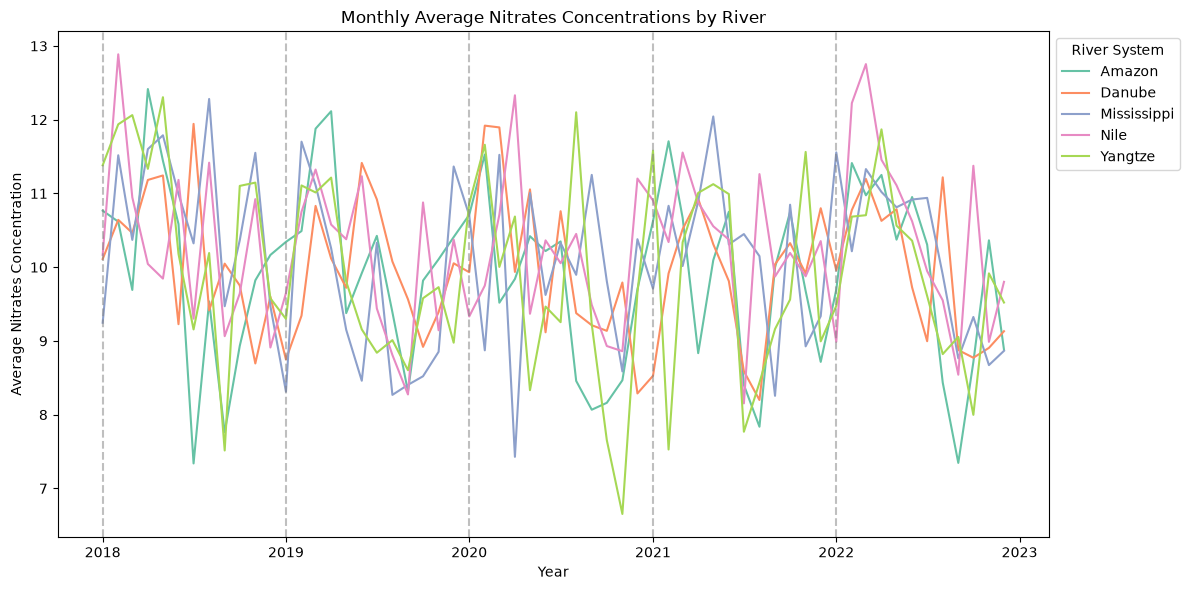

In [65]:
plt.figure(figsize=(12, 6))

sns.lineplot(
    data=monthly_nitrates,
    x='Date',
    y='Nitrates',
    hue='River_System',
    palette='Set2'
)

# Show January labels only
plt.gca().xaxis.set_major_locator(mdates.YearLocator())
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%Y'))

# Add vertical lines to separate each year
for year in range(2018, 2023):
    plt.axvline(
        pd.Timestamp(f'{year}-01-01'),
        color='grey',
        linestyle='--',
        alpha=0.5
    )

# Chart titles and labels
plt.title('Monthly Average Nitrates Concentrations by River')
plt.xlabel('Year')
plt.ylabel('Average Nitrates Concentration')

# Position legend on the right
plt.legend(
    title='River System',
    loc='upper left',
    bbox_to_anchor=(1, 1)
)

# Final formatting
plt.tight_layout()

plt.savefig(
    '../outputs/Monthly_Nitrates_Trends_by_River.png',
    dpi=300,
    bbox_inches='tight'
)
plt.show()

In [41]:
monthly_phosphates = df.groupby(
    [df['Date'].dt.to_period('M'), 'River_System']
)['Phosphates'].mean()

In [42]:
monthly_phosphates = monthly_phosphates.reset_index()

monthly_phosphates['Date'] = pd.to_datetime(
    monthly_phosphates['Date'].astype(str)
)

monthly_phosphates.head()

,Date,River_System,Phosphates
0,2018-01-01,Amazon,0.555300
1,2018-01-01,Danube,0.481515
2,2018-01-01,Mississippi,0.509165
3,2018-01-01,Nile,0.474617
4,2018-01-01,Yangtze,0.543798


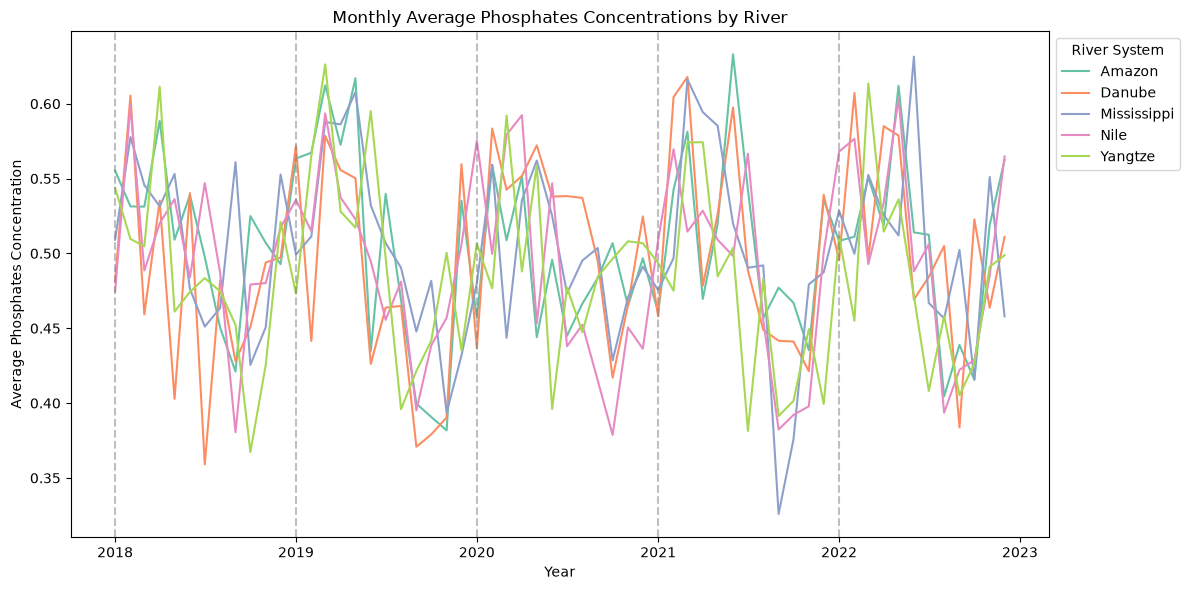

In [66]:
plt.figure(figsize=(12, 6))

sns.lineplot(
    data=monthly_phosphates,
    x='Date',
    y='Phosphates',
    hue='River_System',
    palette='Set2'
)

# Show January labels only
plt.gca().xaxis.set_major_locator(mdates.YearLocator())
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%Y'))

# Add vertical lines to separate each year
for year in range(2018, 2023):
    plt.axvline(
        pd.Timestamp(f'{year}-01-01'),
        color='grey',
        linestyle='--',
        alpha=0.5
    )

# Chart titles and labels
plt.title('Monthly Average Phosphates Concentrations by River')
plt.xlabel('Year')
plt.ylabel('Average Phosphates Concentration')

# Position legend on the right
plt.legend(
    title='River System',
    loc='upper left',
    bbox_to_anchor=(1, 1)
)

# Final formatting
plt.tight_layout()

plt.savefig(
    '../outputs/Monthly_Phosphates_Trends_by_River.png',
    dpi=300,
    bbox_inches='tight'
)
plt.show()

### 6.3 Time-Trend Analysis: Key Findings

Monthly average concentrations were examined across five river systems between 2018 and 2022 for Lead, Mercury, Arsenic, Nitrates and Phosphates.

The time-series visualisations show that toxin concentrations generally fluctuated over the five-year period, with levels rising and falling rather than following a consistent upward or downward trend.

The patterns varied between river systems and across the different substances. This suggests that changes in toxin concentrations were not uniform across all rivers or pollutants.

The monthly averages provide a clearer overview of longer-term changes while reducing the impact of individual measurement fluctuations. However, further statistical analysis would be needed to establish whether the observed variations represent significant trends or recurring seasonal patterns.

In [44]:
ph_correlations = df[
    ['pH_Level', 'Lead', 'Mercury', 'Arsenic', 'Nitrates', 'Phosphates']
].corr()

ph_correlations['pH_Level']

pH_Level      1.000000
Lead          0.325189
Mercury       0.140751
Arsenic       0.043497
Nitrates      0.084319
Phosphates    0.090934
Name: pH_Level, dtype: float64

### 6.4 Correlation Between pH and Toxin Concentrations

Correlation analysis was used to examine the linear relationships between pH levels and five measured substances.

Lead showed the strongest positive correlation with pH (r = 0.325), suggesting that higher pH measurements tended to occur alongside higher lead concentrations. Mercury showed a weaker positive correlation (r = 0.141), while arsenic, nitrates and phosphates had correlations close to zero.

These results suggest that pH has a stronger linear relationship with lead than with the other substances examined. However, correlation does not establish causation and further statistical analysis would be needed to assess the significance of these relationships.

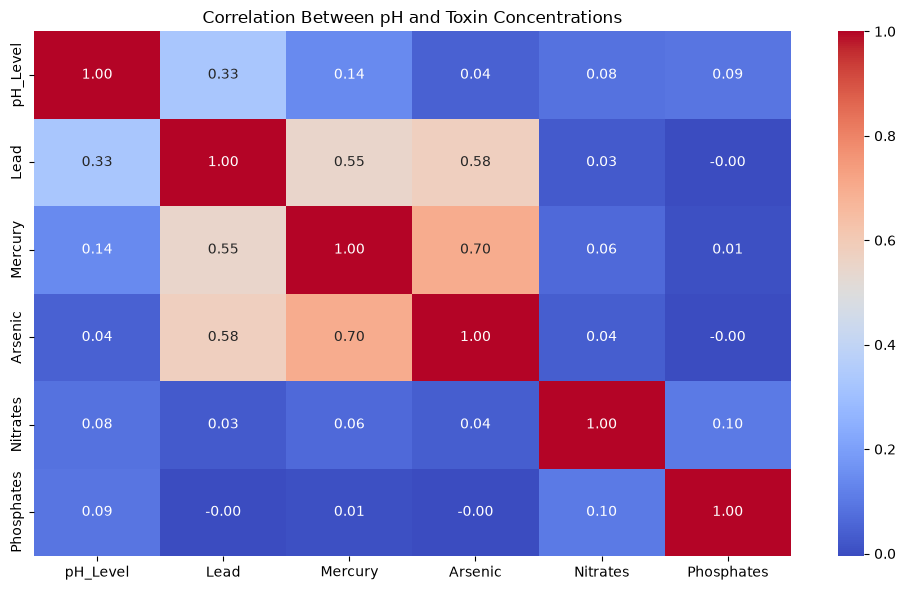

In [67]:
plt.figure(figsize=(10, 6))

sns.heatmap(
    ph_correlations,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Between pH and Toxin Concentrations')
plt.tight_layout()

plt.savefig(
    '../outputs/Toxin_Correlation_Heatmap.png',
    dpi=300,
    bbox_inches='tight'
)
plt.show()

In [46]:
def assign_season(month):
    if month in [12, 1, 2]:
        return 'Winter'
    elif month in [3, 4, 5]:
        return 'Spring'
    elif month in [6, 7, 8]:
        return 'Summer'
    else:
        return 'Autumn'


df['Season'] = df['Date'].dt.month.apply(assign_season)

In [47]:
df['Season'].value_counts()

Season
Spring    330
Summer    330
Autumn    325
Winter    320
Name: count, dtype: int64

In [48]:
seasonal_averages = df.groupby('Season')[
    ['Lead', 'Mercury', 'Arsenic', 'Nitrates', 'Phosphates']
].mean()

seasonal_averages

,Lead,Mercury,Arsenic,Nitrates,Phosphates
Season,,,,,
Autumn,2.856070,0.556725,3.533620,9.353001,0.442976
Spring,3.135579,0.636664,3.683077,10.756253,0.544293
Summer,2.963871,0.582851,3.576617,9.863775,0.484979
Winter,3.087940,0.608145,3.598019,10.178403,0.515318


### 6.5 Seasonal Analysis: Initial Findings

The average concentrations of all five measured substances were highest in Spring and lowest in Autumn.

Spring recorded the highest average concentrations of Lead, Mercury, Arsenic, Nitrates and Phosphates. Autumn recorded the lowest averages for each substance.

This consistent pattern suggests that seasonal variation may be present within the dataset. However, the results represent averages across all five river systems and may conceal differences between individual rivers.

Further analysis is required to investigate the distribution of toxin measurements across seasons and determine whether the observed differences are statistically significant.

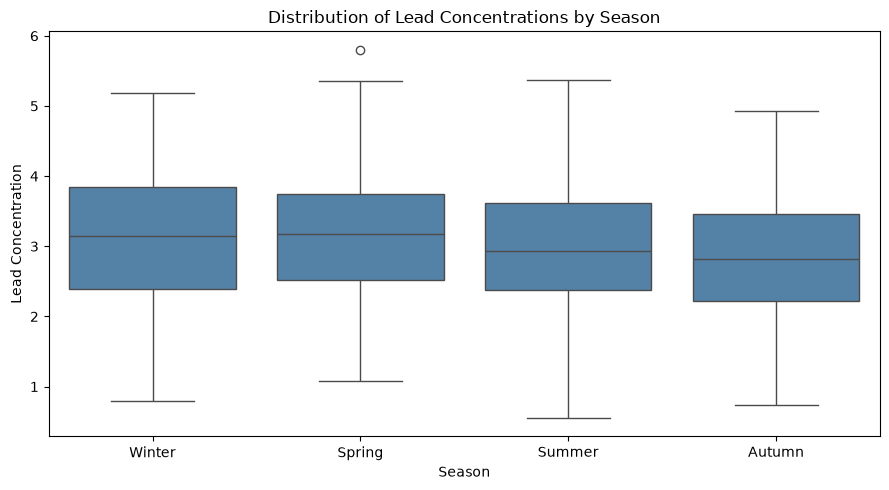

In [68]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x='Season',
    y='Lead',
    order=['Winter', 'Spring', 'Summer', 'Autumn'],
    color='steelblue'
)

plt.title('Distribution of Lead Concentrations by Season')
plt.xlabel('Season')
plt.ylabel('Lead Concentration')

plt.tight_layout()

plt.savefig(
    '../outputs/Seasonal_Lead_Distribution.png',
    dpi=300,
    bbox_inches='tight'
)
plt.show()

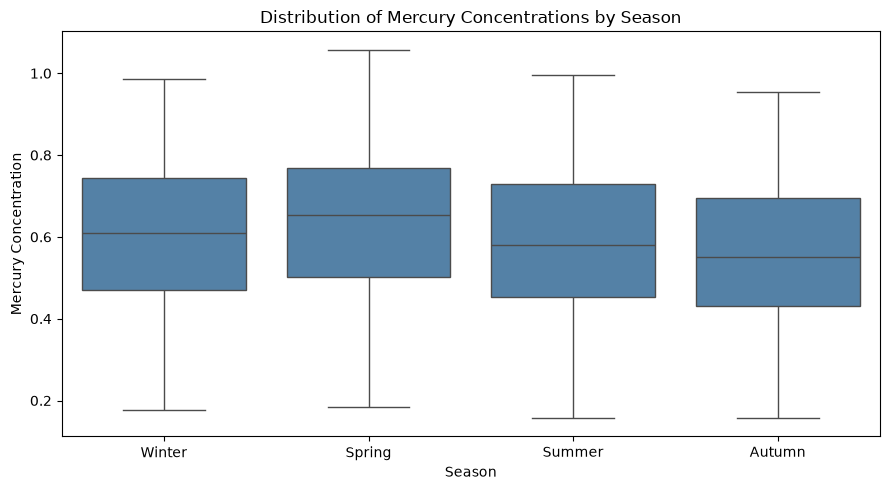

In [69]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x='Season',
    y='Mercury',
    order=['Winter', 'Spring', 'Summer', 'Autumn'],
    color='steelblue'
)

plt.title('Distribution of Mercury Concentrations by Season')
plt.xlabel('Season')
plt.ylabel('Mercury Concentration')

plt.tight_layout()

plt.savefig(
    '../outputs/Seasonal_Mercury_Distribution.png',
    dpi=300,
    bbox_inches='tight'
)
plt.show()

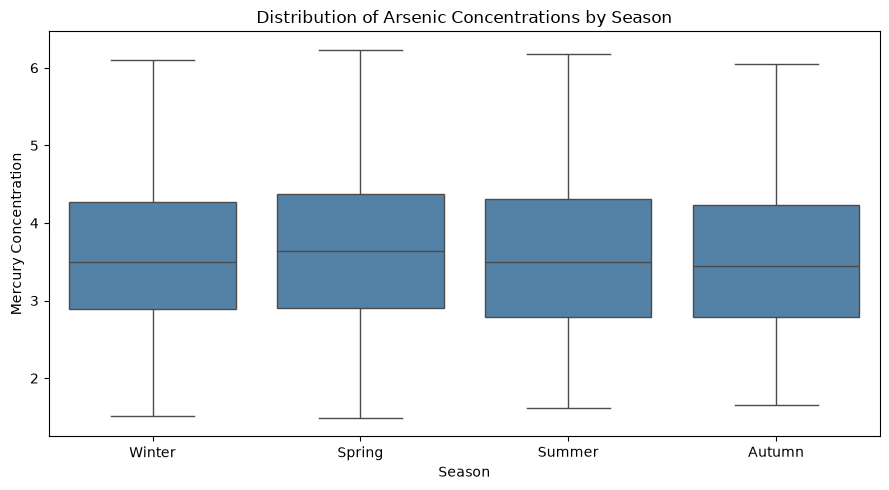

In [70]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x='Season',
    y='Arsenic',
    order=['Winter', 'Spring', 'Summer', 'Autumn'],
    color='steelblue'
)

plt.title('Distribution of Arsenic Concentrations by Season')
plt.xlabel('Season')
plt.ylabel('Mercury Concentration')

plt.tight_layout()

plt.savefig(
    '../outputs/Seasonal_Arsenic_Distribution.png',
    dpi=300,
    bbox_inches='tight'
)
plt.show()

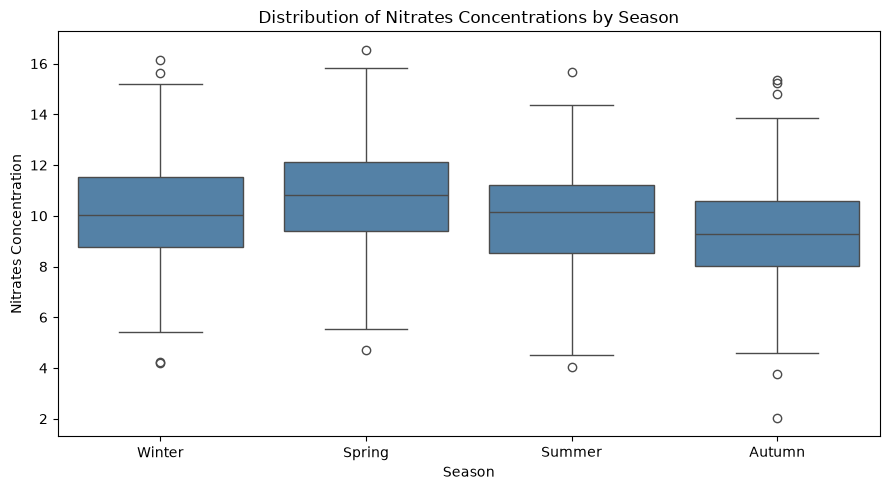

In [71]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x='Season',
    y='Nitrates',
    order=['Winter', 'Spring', 'Summer', 'Autumn'],
    color='steelblue'
)

plt.title('Distribution of Nitrates Concentrations by Season')
plt.xlabel('Season')
plt.ylabel('Nitrates Concentration')

plt.tight_layout()

plt.savefig(
    '../outputs/Seasonal_Nitrates_Distribution.png',
    dpi=300,
    bbox_inches='tight'
)
plt.show()

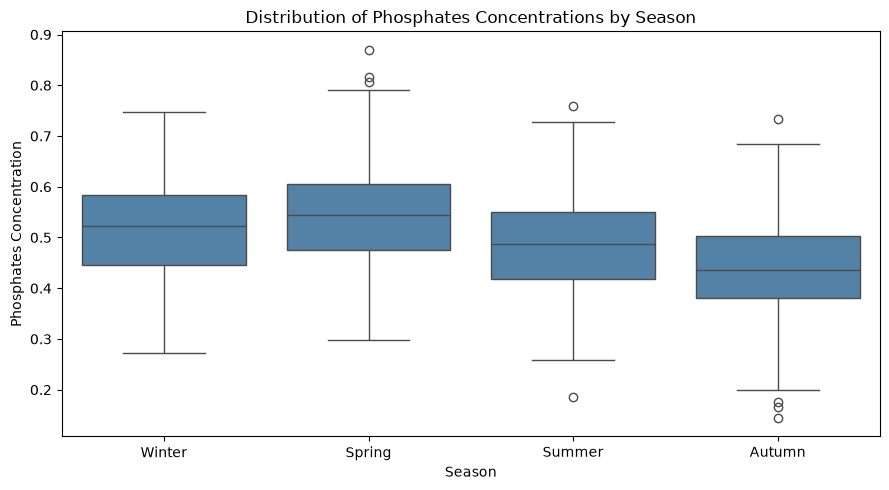

In [72]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x='Season',
    y='Phosphates',
    order=['Winter', 'Spring', 'Summer', 'Autumn'],
    color='steelblue'
)

plt.title('Distribution of Phosphates Concentrations by Season')
plt.xlabel('Season')
plt.ylabel('Phosphates Concentration')

plt.tight_layout()

plt.savefig(
    '../outputs/Seasonal_Phosphates_Distribution.png',
    dpi=300,
    bbox_inches='tight'
)
plt.show()

### 6.6 Seasonal Box Plot Analysis: Key Findings

The seasonal box plots show differences in the distribution of toxin concentrations across the four seasons.

Key observations:

- Spring generally has higher median concentrations across the five substances, while Autumn tends to have lower medians.
- Phosphates displays numerous potential outliers in Spring, Summer and Autumn, but not Winter.
- Nitrates displays numerous potential outliers across all four seasons.
- Lead has one potential outlier in Spring.

The box plots provide additional information beyond seasonal averages by showing the spread, median and potential outliers within each season.

The presence of potential outliers suggests considerable variation in some individual measurements. These observations may warrant further investigation, although the box plots alone do not establish whether seasonal differences are statistically significant.

In [54]:
yangtze_lead = df[df['River_System'] == 'Yangtze']['Lead'].dropna()

amazon_lead = df[df['River_System'] == 'Amazon']['Lead'].dropna()

In [55]:
print("Yangtze observations:", len(yangtze_lead))
print("Amazon observations:", len(amazon_lead))

Yangtze observations: 258
Amazon observations: 257


In [56]:
t_statistic, p_value = stats.ttest_ind(
    yangtze_lead,
    amazon_lead,
    equal_var=False
)

print("T-statistic:", t_statistic)
print("P-value:", p_value)

T-statistic: 45.32514178061547
P-value: 4.894737530928009e-181


In [57]:
regression_data = df[['pH_Level', 'Lead']].dropna()

regression_data.shape

(1259, 2)

In [58]:
regression_result = linregress(
    regression_data['pH_Level'],
    regression_data['Lead']
)

print(regression_result)

LinregressResult(slope=np.float64(0.8168051493581401), intercept=np.float64(-2.996733836579928), rvalue=np.float64(0.32518850039810315), pvalue=np.float64(2.137346801280923e-32), stderr=np.float64(0.06699551278646836), intercept_stderr=np.float64(0.49319349210787583))


In [59]:
r_squared = regression_result.rvalue ** 2

print("R-squared:", r_squared)
print("Percentage explained:", r_squared * 100)

R-squared: 0.10574756079116714
Percentage explained: 10.574756079116714


### 6.7 Linear Regression: pH and Lead Concentrations

Simple linear regression was used to investigate whether pH levels could predict Lead concentrations.

The model identified a positive relationship between pH and Lead, with a slope of approximately 0.817. This suggests that a one-unit increase in pH is associated with an estimated increase of 0.817 in Lead concentration.

The relationship was statistically significant (p < 0.05). However, the R-squared value was approximately 0.106, meaning that pH explained only 10.57% of the variation in Lead concentrations.

This indicates that pH alone is a relatively weak predictor of Lead concentration. Other factors are likely to contribute to the variation observed.

Although a statistically significant relationship was identified, the model has limited predictive power.

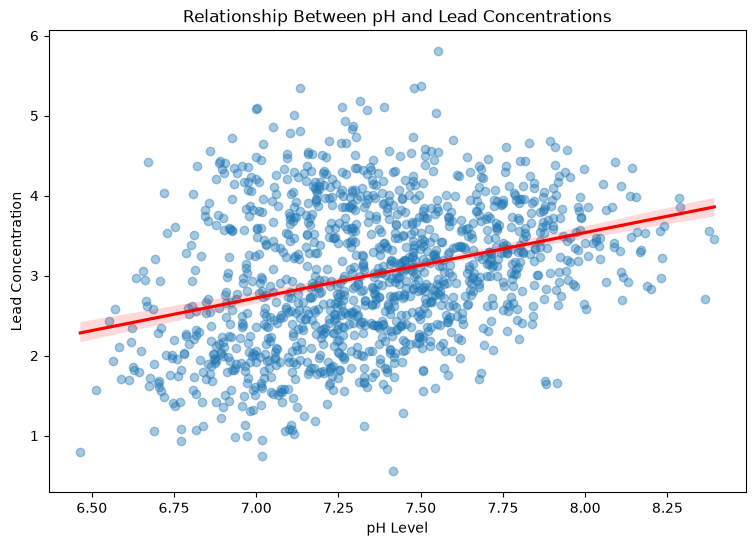

In [73]:
plt.figure(figsize=(9, 6))

sns.regplot(
    data=regression_data,
    x='pH_Level',
    y='Lead',
    scatter_kws={'alpha': 0.4},
    line_kws={'color': 'red'}
)

plt.title('Relationship Between pH and Lead Concentrations')
plt.xlabel('pH Level')
plt.ylabel('Lead Concentration')

plt.tight_layout

plt.savefig(
    '../outputs/pH_and_Lead_Regression.png',
    dpi=300,
    bbox_inches='tight'
)
plt.show()

### 6.8 Regression Visualisation: Interpretation

The scatter plot shows a positive relationship between pH levels and Lead concentrations, represented by the upward-sloping regression line.

However, the observations are widely dispersed around the line, indicating that the relationship is relatively weak. This supports the R-squared result, which showed that pH explains only 10.57% of the variation in Lead concentrations.

The visualisation reinforces the conclusion that pH alone has limited predictive power for Lead concentrations.

# 7. Environmental Toxin Analysis: Findings and Recommendations for EcoGuard

## Purpose and Approach

This project investigated water-quality measurements across five major river systems between 2018 and 2022. Using Python, exploratory data analysis, statistical testing and visualisations, the analysis examined differences in toxin concentrations, changes over time, seasonal patterns and relationships between pH and toxin levels.

## Key Findings

The Yangtze recorded the highest average concentrations of Lead, Mercury and Arsenic, while the Nile had the highest average Nitrates concentration. The Amazon recorded the highest average Phosphates concentration, although differences between rivers were small.

Monthly averages showed that toxin concentrations fluctuated over the five-year period, without a consistent overall upward or downward trend. Seasonal analysis identified higher average concentrations across all five toxins in Spring and lower averages in Autumn.

The correlation analysis identified a positive relationship between pH and Lead concentrations (r = 0.33), while relationships between pH and the other toxins were weak. An independent-samples Welch's t-test found a statistically significant difference in average Lead concentrations between the Yangtze and Amazon. Linear regression confirmed a positive relationship between pH and Lead, but pH explained only 10.57% of the variation, indicating limited predictive power.

## Interpretation and Limitations

The findings highlight differences in toxin concentrations between river systems and suggest potential seasonal variation. However, the dataset does not specify measurement units or provide regulatory thresholds. Consequently, the results cannot establish whether any measurements exceed environmental safety limits. Seasonal classifications also follow Northern Hemisphere conventions, which may not reflect local seasons for every river. Correlation and regression identify associations rather than causal relationships.

## Recommendations

EcoGuard should prioritise further monitoring of Lead, Mercury and Arsenic in the Yangtze, alongside Nitrates monitoring in the Nile. Seasonal monitoring should investigate the higher averages observed in Spring. Additional measurements and environmental information are needed to understand the factors contributing to variations in toxin concentrations.

EcoGuard should also obtain measurement units, sampling methodology and relevant environmental standards to enable meaningful assessment against regulatory limits. Continued monitoring across all five river systems would help establish longer-term patterns and support evidence-based conservation and policy decisions.

## 8. Key Insights

1. **Higher concentrations in the Yangtze:** The Yangtze recorded the highest average concentrations of Lead, Mercury and Arsenic across the five river systems.

2. **Different patterns across pollutants:** The Nile had the highest average Nitrates concentration, while the Amazon had the highest average Phosphates concentration.

3. **Seasonal variation:** Spring recorded the highest average concentrations across all five toxins, while Autumn recorded the lowest.

4. **Relationship between pH and Lead:** A positive correlation was identified between pH and Lead concentrations, although pH explained only 10.57% of the variation in Lead.

5. **Changes over time:** Toxin concentrations fluctuated throughout the five-year period, without a consistent overall upward or downward trend.